# Serie II: experimento aislado de features físicas

**Ridge con quince señales sigue como campeona.** Este notebook contrasta tres hipótesis sin sobrescribir notebook 07, su decisión, artefacto ni resultados. No evalúa el quinto día.

Diseño previamente propuesto en [features físicas](../docs/serie2-propuesta-features.md): aire × oxígeno medio, magnitud de la asimetría de oxígenos y agua × temperatura global. Son hipótesis predictivas, no balances de energía ni efectos causales. No hay rezagos ni búsqueda de hiperparámetros.

Cada hipótesis se evalúa sola y con controles de sensores: (a) base de quince + feature; (b) base + soportes originales ausentes, sin feature; (c) ese control + feature. El tercer brazo permite distinguir una interacción nueva de la recuperación de otro sensor. Es el mismo Ridge alpha=100 en todas las comparaciones.

Se valorarán MAE medio, peor día, sesgo, p95 y consistencia por ventana. Se propone conservar como candidata solo si reduce error sin deteriorar el peor día; se examina además la contribución frente al control. No hay promoción automática ni umbral económico validado. Las validaciones ya utilizadas ofrecen evidencia exploratoria, sin test independiente nuevo.

Para decidir si compensa ampliar el modelo se aplica también la regla de parsimonia ya vigente en el notebook 07: candidatos a ≤1 % del MAE mínimo y peor MAE a ≤5 % del peor día del mínimo; entre ellos se prefiere menor número de entradas. Son tolerancias técnicas heredadas, no un umbral económico nuevo.

In [1]:
from pathlib import Path
import hashlib
import json
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.linear_model import Ridge
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from threadpoolctl import threadpool_limits

raiz = next(p for p in [Path.cwd(), Path.cwd().parent] if (p / 'scripts/modelado_serie2.py').exists())
sys.path.insert(0, str(raiz))
from scripts.modelado_serie2 import OBJETIVO, seleccionar_variables, calcular_metricas
from experimentos.features_fisicas_serie2 import SOPORTES, preparar_entradas

salida = raiz / 'outputs/experimento_features'
salida.mkdir(exist_ok=True)
# Registrar huellas antes de cualquier escritura experimental.
protegidos = [*sorted((raiz / 'outputs').glob('serie2_*')),
              raiz / 'notebooks/07_sensor_virtual_serie2.ipynb',
              raiz / 'scripts/modelado_serie2.py', raiz / 'data/raw/serie2/data.csv']
huellas_antes = {str(p.relative_to(raiz)): hashlib.sha256(p.read_bytes()).hexdigest() for p in protegidos if p.is_file()}

## Datos y ventanas

La fuente permanece intacta. Se conserva la primera fila de cada pareja, como el notebook 07. Solo se modelan los cuatro primeros bloques de 24 horas. Cada entrenamiento termina cinco minutos antes de su validación de 24 horas; RFE se vuelve a ajustar solo con ese entrenamiento. Las filas fuera de rejilla o del alcance experimental se exportan con motivo, sin declararlas erróneas.

In [2]:
datos = pd.read_csv(raiz / 'data/raw/serie2/data.csv', parse_dates=['date'])
base = datos.columns.drop(['date', OBJETIVO]).tolist()
inicio = datos.date.iloc[0]
fin_desarrollo = inicio + pd.Timedelta(days=4)
assert datos.date.is_unique and datos.date.is_monotonic_increasing
assert datos.date.diff().dropna().eq(pd.Timedelta(seconds=5)).all()
assert datos[OBJETIVO].iloc[::2].reset_index(drop=True).equals(datos[OBJETIVO].iloc[1::2].reset_index(drop=True))
fase = np.arange(len(datos)) % 2 == 0
periodo = datos.date.lt(fin_desarrollo)
usadas = fase & periodo
fuera = datos.loc[~usadas].copy()
fuera.insert(0, 'fila_fuente', fuera.index)
fuera['motivo'] = np.where(fuera.date.ge(fin_desarrollo),
                          'Quinto día: fuera de este experimento',
                          'Segunda lectura del par: fuera de rejilla, no inválida')
fuera.to_csv(salida / 'filas_fuera_experimento.csv', index=False)
# A partir de aquí no se consultan etiquetas ni entradas del quinto día.
trabajo = datos.loc[usadas].copy()
trabajo.insert(0, 'fila_fuente', trabajo.index)
trabajo = trabajo.reset_index(drop=True)
X, y, fechas = trabajo[base], trabajo[OBJETIVO], trabajo.date
trabajo[['fila_fuente', 'date']].to_csv(salida / 'filas_modelado.csv', index=False)
assert len(trabajo) == 34560 and len(fuera) == 51840
assert len(trabajo) + len(fuera) == len(datos)
assert OBJETIVO not in X and fechas.max() < fin_desarrollo
assert np.isfinite(y).all()
print(f'Fuente: {len(datos):,}; modelado: {len(trabajo):,}; fuera: {len(fuera):,}')
display(fuera.motivo.value_counts().to_frame('filas'))

pliegues, particiones, papeles = [], [], []
for dia in [1, 2, 3]:
    limite = inicio + pd.Timedelta(days=dia)
    entrenar = fechas.lt(limite - pd.Timedelta(minutes=5))
    validar = fechas.ge(limite) & fechas.lt(limite + pd.Timedelta(days=1))
    assert fechas[entrenar].max() < fechas[validar].min() - pd.Timedelta(minutes=5)
    nombre = f'Validación {dia}'
    pliegues.append((nombre, entrenar, validar))
    particiones.append(dict(particion=nombre, n_entrenamiento=int(entrenar.sum()), n_evaluacion=int(validar.sum()),
                            inicio_entrenamiento=str(fechas[entrenar].min()), fin_entrenamiento=str(fechas[entrenar].max()),
                            inicio_evaluacion=str(fechas[validar].min()), fin_evaluacion=str(fechas[validar].max())))
    papel = np.select([entrenar, validar, fechas.ge(limite-pd.Timedelta(minutes=5)) & fechas.lt(limite)],
                      ['entrenamiento', 'validacion', 'separacion'], default='otro periodo')
    papeles.append(trabajo[['fila_fuente', 'date']].assign(particion=nombre, papel=papel))
pd.DataFrame(particiones).to_csv(salida / 'particiones.csv', index=False)
pd.concat(papeles).to_csv(salida / 'papel_por_fila.csv', index=False)
display(pd.DataFrame(particiones))

Fuente: 86,400; modelado: 34,560; fuera: 51,840


,filas
motivo,
"Segunda lectura del par: fuera de rejilla, no inválida",34560
Quinto día: fuera de este experimento,17280


,particion,n_entrenamiento,n_evaluacion,inicio_entrenamiento,fin_entrenamiento,inicio_evaluacion,fin_evaluacion
0,Validación 1,8610,8640,2022-03-27 14:28:54,2022-03-28 14:23:44,2022-03-28 14:28:54,2022-03-29 14:28:44
1,Validación 2,17250,8640,2022-03-27 14:28:54,2022-03-29 14:23:44,2022-03-29 14:28:54,2022-03-30 14:28:44
2,Validación 3,25890,8640,2022-03-27 14:28:54,2022-03-30 14:23:44,2022-03-30 14:28:54,2022-03-31 14:28:44


## Comparaciones fijadas

Se recalculan las quince entradas en cada pliegue. Se guarda cuántas columnas usa Ridge y cuántos sensores necesita cada variante: una feature puede requerir un sensor que RFE dejó fuera. Las medianas, medias y desviaciones se ajustan solo en entrenamiento. Para los productos se centran/normalizan primero sus dos componentes; después se escala toda la matriz, como en la campeona. Las fórmulas y su preparación están aisladas en `experimentos/features_fisicas_serie2.py`.

No se prueban combinaciones de las tres features ni otros valores de alpha. No se ajusta nada observando el último día.

In [3]:
resultados, predicciones, coeficientes, selecciones, ajustes = [], [], [], [], []
for nombre, entrenar, validar in pliegues:
    with threadpool_limits(limits=2):
        quince, _ = seleccionar_variables(X.loc[entrenar], y[entrenar])
        selecciones.extend(dict(particion=nombre, sensor=c) for c in quince)
        variantes = [('Base 15', None, 'base', quince, None)]
        for candidata, soportes in SOPORTES.items():
            union = list(dict.fromkeys([*quince, *soportes]))
            variantes.extend([
                (f'{candidata} | sola', candidata, 'sola', quince, candidata),
                (f'{candidata} | control', candidata, 'control', union, None),
                (f'{candidata} | completa', candidata, 'completa', union, candidata),
            ])
        for variante, candidata, brazo, lineales, formula in variantes:
            train, evaluacion, ajuste = preparar_entradas(X.loc[entrenar], X.loc[validar], lineales, formula)
            modelo = make_pipeline(StandardScaler(), Ridge(alpha=100)).fit(train, y[entrenar])
            estimado = modelo.predict(evaluacion)
            resultados.append(dict(particion=nombre, variante=variante, candidata=candidata, brazo=brazo,
                                   n_entradas=train.shape[1], n_sensores=len(ajuste['sensores_requeridos']),
                                   **calcular_metricas(y[validar], estimado)))
            predicciones.append(pd.DataFrame(dict(fila_fuente=trabajo.loc[validar, 'fila_fuente'], date=fechas[validar],
                                                  observado=y[validar], estimado=estimado, particion=nombre, variante=variante)))
            coeficientes.extend(dict(particion=nombre, variante=variante, entrada=c, coeficiente_estandarizado=float(b))
                                for c,b in zip(train.columns, modelo[-1].coef_))
            ajustes.append(dict(particion=nombre, variante=variante, **ajuste))
    print(nombre, 'completada: diez variantes fijadas', flush=True)
metricas = pd.DataFrame(resultados)
preds = pd.concat(predicciones, ignore_index=True)
metricas.to_csv(salida / 'metricas_validacion.csv', index=False)
preds.to_csv(salida / 'predicciones_validacion.csv', index=False)
pd.DataFrame(coeficientes).to_csv(salida / 'coeficientes.csv', index=False)
pd.DataFrame(selecciones).to_csv(salida / 'selecciones_por_pliegue.csv', index=False)
(salida / 'ajustes_entrenamiento.json').write_text(json.dumps(ajustes, ensure_ascii=False, indent=2, allow_nan=False), encoding='utf-8')

# La base debe reproducir el experimento campeón existente antes de interpretar diferencias.
anterior = pd.read_csv(raiz / 'outputs/serie2_validacion.csv')
anterior = anterior.loc[anterior.modelo.eq('Ridge') & anterior.variante.eq('Reducida 15')].set_index('particion')
actual = metricas.loc[metricas.brazo.eq('base')].set_index('particion')
for metrica in ['MAE', 'RMSE', 'R2', 'sesgo', 'WAPE_pct', 'error_abs_p95']:
    np.testing.assert_allclose(actual.loc[anterior.index, metrica], anterior[metrica], rtol=0, atol=1e-10)
print('Base de quince reproducida: mismas métricas que notebook 07.')

Validación 1 completada: diez variantes fijadas


Validación 2 completada: diez variantes fijadas


Validación 3 completada: diez variantes fijadas


Base de quince reproducida: mismas métricas que notebook 07.


In [4]:
resumen = metricas.groupby(['variante', 'brazo'], as_index=False).agg(
    MAE_medio=('MAE', 'mean'), MAE_peor_dia=('MAE', 'max'), RMSE_medio=('RMSE', 'mean'),
    sesgo_medio=('sesgo', 'mean'), p95_medio=('error_abs_p95', 'mean'),
    entradas_min=('n_entradas', 'min'), entradas_max=('n_entradas', 'max'),
    sensores_min=('n_sensores', 'min'), sensores_max=('n_sensores', 'max'))
resumen.to_csv(salida / 'resumen.csv', index=False)
mae_base = actual.MAE.mean()
comparaciones = []
for candidata in SOPORTES:
    sola = metricas.loc[metricas.variante.eq(f'{candidata} | sola')].set_index('particion')
    control = metricas.loc[metricas.variante.eq(f'{candidata} | control')].set_index('particion')
    completa = metricas.loc[metricas.variante.eq(f'{candidata} | completa')].set_index('particion')
    comparaciones.append(dict(
        candidata=candidata, MAE_base=mae_base, MAE_sola=sola.MAE.mean(),
        cambio_sola_vs_base_pct=100*(sola.MAE.mean()/mae_base-1),
        peor_dia_base=actual.MAE.max(), peor_dia_sola=sola.MAE.max(),
        dias_mejora_sola=int((sola.MAE < actual.MAE).sum()),
        MAE_control=control.MAE.mean(), MAE_completa=completa.MAE.mean(),
        cambio_completa_vs_control_pct=100*(completa.MAE.mean()/control.MAE.mean()-1),
        dias_mejora_vs_control=int((completa.MAE < control.MAE).sum()),
        peor_dia_completa=completa.MAE.max()))
comparacion = pd.DataFrame(comparaciones)
comparacion.to_csv(salida / 'comparacion.csv', index=False)
display(comparacion.round(6))
display(metricas.pivot(index='variante', columns='particion', values='MAE').round(6))
display(resumen.sort_values('MAE_medio').round(6))

# Bloques de seis horas desde el inicio de cada validación: doce por variante.
bloques = []
for (particion, variante), tramo in preds.groupby(['particion', 'variante']):
    grupos = ((tramo.date-tramo.date.min()).dt.total_seconds() // 21600).astype(int)+1
    for bloque, g in tramo.groupby(grupos):
        bloques.append(dict(particion=particion, variante=variante, bloque_6h=int(bloque), filas=len(g),
                            **calcular_metricas(g.observado, g.estimado)))
pd.DataFrame(bloques).to_csv(salida / 'metricas_bloques_6h.csv', index=False)

# Regla de parsimonia heredada de notebook 07, sin modificar tolerancias.
eleccion = metricas.groupby('variante', as_index=False).agg(
    MAE_medio=('MAE','mean'), MAE_peor_dia=('MAE','max'), entradas_medias=('n_entradas','mean'))
mejor = eleccion.loc[eleccion.MAE_medio.idxmin()]
comparables = eleccion.loc[eleccion.MAE_medio.le(mejor.MAE_medio*1.01)
                           & eleccion.MAE_peor_dia.le(mejor.MAE_peor_dia*1.05)]
recomendada = comparables.sort_values(['entradas_medias','MAE_medio']).iloc[0]
decision_experimental = dict(
    variante_recomendada=recomendada.variante,
    menor_MAE_observado=mejor.variante,
    MAE_minimo=float(mejor.MAE_medio),
    MAE_recomendado=float(recomendada.MAE_medio),
    criterio='Regla heredada: 1 % en MAE, 5 % en peor día; preferir menos entradas',
    promocion_automatica=False, comprobacion_final_evaluada=False)
(salida/'decision_experimental.json').write_text(json.dumps(decision_experimental, ensure_ascii=False, indent=2), encoding='utf-8')
print(json.dumps(decision_experimental, ensure_ascii=False, indent=2))


,candidata,MAE_base,MAE_sola,cambio_sola_vs_base_pct,peor_dia_base,peor_dia_sola,dias_mejora_sola,MAE_control,MAE_completa,cambio_completa_vs_control_pct,dias_mejora_vs_control,peor_dia_completa
0,aire_x_oxigeno,0.457279,0.458538,0.275172,0.515948,0.517742,0,0.457096,0.458338,0.271745,0,0.517492
1,asimetria_oxigeno,0.457279,0.457544,0.057931,0.515948,0.515877,2,0.457167,0.457447,0.061290,2,0.515587
2,agua_x_temperatura,0.457279,0.456633,-0.141270,0.515948,0.515175,2,0.457215,0.456772,-0.097015,2,0.516052


particion,Validación 1,Validación 2,Validación 3
variante,,,
Base 15,0.515948,0.484420,0.371470
agua_x_temperatura | completa,0.516052,0.475188,0.379075
agua_x_temperatura | control,0.516551,0.483625,0.371470
agua_x_temperatura | sola,0.515175,0.475649,0.379075
aire_x_oxigeno | completa,0.517492,0.486380,0.371142
aire_x_oxigeno | control,0.515612,0.485716,0.369959
aire_x_oxigeno | sola,0.517742,0.485130,0.372742
asimetria_oxigeno | completa,0.515587,0.485621,0.371134
asimetria_oxigeno | control,0.515612,0.484420,0.371470


,variante,brazo,MAE_medio,MAE_peor_dia,RMSE_medio,sesgo_medio,p95_medio,entradas_min,entradas_max,sensores_min,sensores_max
3,agua_x_temperatura | sola,sola,0.456633,0.515175,0.585080,0.057930,1.170488,16,16,15,16
1,agua_x_temperatura | completa,completa,0.456772,0.516052,0.585345,0.059080,1.171962,16,17,15,16
5,aire_x_oxigeno | control,control,0.457096,0.515612,0.585656,0.072649,1.169899,16,16,16,16
8,asimetria_oxigeno | control,control,0.457167,0.515612,0.585948,0.063554,1.168532,15,16,15,16
2,agua_x_temperatura | control,control,0.457215,0.516551,0.586284,0.066288,1.169911,15,16,15,16
0,Base 15,base,0.457279,0.515948,0.586251,0.065202,1.170510,15,15,15,15
7,asimetria_oxigeno | completa,completa,0.457447,0.515587,0.586336,0.065304,1.169498,16,17,15,16
9,asimetria_oxigeno | sola,sola,0.457544,0.515877,0.586475,0.065249,1.170231,16,16,15,16
4,aire_x_oxigeno | completa,completa,0.458338,0.517492,0.587075,0.068991,1.174993,17,17,16,16
6,aire_x_oxigeno | sola,sola,0.458538,0.517742,0.587669,0.061420,1.174425,16,16,16,16


{
  "variante_recomendada": "Base 15",
  "menor_MAE_observado": "agua_x_temperatura | sola",
  "MAE_minimo": 0.4566333027748403,
  "MAE_recomendado": 0.45727929914873117,
  "criterio": "Regla heredada: 1 % en MAE, 5 % en peor día; preferir menos entradas",
  "promocion_automatica": false,
  "comprobacion_final_evaluada": false
}


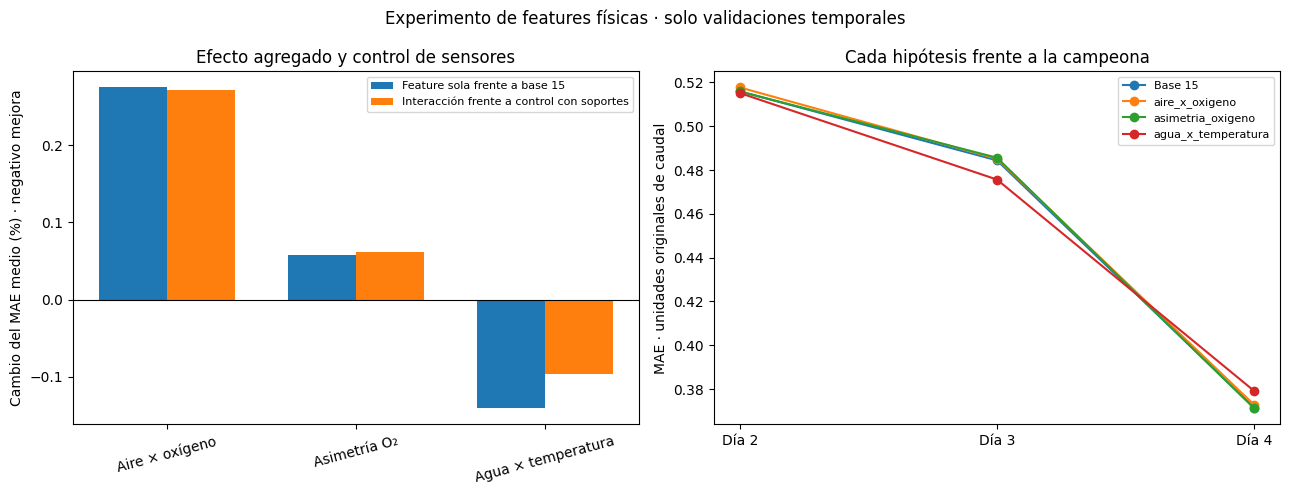

In [5]:
fig, ejes = plt.subplots(1, 2, figsize=(13, 5))
x = np.arange(len(comparacion))
ejes[0].bar(x-0.18, comparacion.cambio_sola_vs_base_pct, width=.36, label='Feature sola frente a base 15')
ejes[0].bar(x+0.18, comparacion.cambio_completa_vs_control_pct, width=.36, label='Interacción frente a control con soportes')
ejes[0].axhline(0, color='black', linewidth=.8)
ejes[0].set_xticks(x, ['Aire × oxígeno', 'Asimetría O₂', 'Agua × temperatura'], rotation=15)
ejes[0].set_ylabel('Cambio del MAE medio (%) · negativo mejora')
ejes[0].set_title('Efecto agregado y control de sensores')
ejes[0].legend(fontsize=8)
for variante in ['Base 15', *[f'{c} | sola' for c in SOPORTES]]:
    tramo = metricas.loc[metricas.variante.eq(variante)]
    ejes[1].plot([1,2,3], tramo.MAE, marker='o', label=variante.replace(' | sola',''))
ejes[1].set_xticks([1,2,3], ['Día 2', 'Día 3', 'Día 4'])
ejes[1].set_ylabel('MAE · unidades originales de caudal')
ejes[1].set_title('Cada hipótesis frente a la campeona')
ejes[1].legend(fontsize=8)
fig.suptitle('Experimento de features físicas · solo validaciones temporales')
fig.tight_layout()
fig.savefig(salida / 'comparacion.png', dpi=150, bbox_inches='tight')
plt.show()

## Verificación independiente y protección de la campeona

Se reconstruyen las métricas desde las predicciones, sin usar la función de métricas compartida. Se revisa que el objetivo coincida con el original por timestamp, que cada ventana conserve 8,640 evaluaciones y que todas las huellas protegidas permanezcan idénticas. Los resultados de este notebook quedan únicamente en `outputs/experimento_features/`, ignorado por Git.

In [6]:
fuente = trabajo.set_index('date')
for _, g in preds.groupby(['particion', 'variante']):
    assert len(g) == 8640 and g.date.is_unique
    np.testing.assert_allclose(g.observado, fuente.loc[g.date, OBJETIVO], rtol=0, atol=1e-12)
for _, fila in metricas.iterrows():
    g = preds.loc[preds.particion.eq(fila.particion) & preds.variante.eq(fila.variante)]
    error = g.estimado-g.observado
    independientes = dict(MAE=error.abs().mean(), RMSE=np.sqrt((error**2).mean()),
                          R2=1-(error**2).sum()/((g.observado-g.observado.mean())**2).sum(),
                          sesgo=error.mean(), WAPE_pct=100*error.abs().sum()/g.observado.abs().sum(),
                          error_abs_p95=error.abs().quantile(.95))
    for metrica, valor in independientes.items():
        np.testing.assert_allclose(valor, fila[metrica], rtol=0, atol=1e-12)
huellas_despues = {nombre: hashlib.sha256((raiz/nombre).read_bytes()).hexdigest() for nombre in huellas_antes}
assert huellas_antes == huellas_despues
verificacion = dict(variantes=metricas.variante.nunique(), particiones=3, predicciones=len(preds),
                    filas_modelado=len(trabajo), filas_fuera=len(fuera),
                    campeona_sin_cambios=True, quinto_dia_evaluado=False,
                    base_reproducida=True, metricas_reconstruidas=True, huellas_protegidas=huellas_antes)
(salida/'verificacion.json').write_text(json.dumps(verificacion, ensure_ascii=False, indent=2), encoding='utf-8')
print('Verificación completa:', len(preds), 'predicciones; campeona y fuente intactas; quinto día no evaluado.')

Verificación completa: 259200 predicciones; campeona y fuente intactas; quinto día no evaluado.


## Conclusiones y decisión gerencial

**Se mantiene Ridge con quince señales.** Su MAE medio de validación es 0.457279. No se reemplaza ni reentrena el artefacto campeón.

| Hipótesis añadida sola a la base | MAE medio | Cambio frente a base | Días que mejora |
| --- | ---: | ---: | ---: |
| Aire × oxígeno | 0.458538 | +0.275 % | 0 de 3 |
| Asimetría de oxígeno | 0.457544 | +0.058 % | 2 de 3 |
| Agua × temperatura | 0.456633 | −0.141 % | 2 de 3 |

Un cambio negativo reduce el error. Las cifras se reproducen en las tablas anteriores y en `outputs/experimento_features/comparacion.csv`.

- **Aire × oxígeno:** empeora las tres ventanas. El control con sensores originales tampoco rescata la interacción: agregarla a ese control empeora el promedio 0.272 %. Su coeficiente cambia de signo. No se recomienda incorporarla con esta definición.
- **Asimetría:** mejora ligeramente dos ventanas y el peor día, pero empeora el MAE medio. Frente al control con los mismos sensores también empeora 0.061 %. No se recomienda incorporarla.
- **Agua × temperatura:** es la única mejora media, pero pequeña y desigual. Frente a la base cambia −0.150 %, −1.811 % y +2.047 % por día. El control de temperatura sin interacción da MAE 0.457215; agregar la interacción a ese control baja a 0.456772 (−0.097 %). Hay una señal exploratoria que no se explica solo por recuperar temperatura, pero no es uniforme. El coeficiente de la interacción es negativo en los tres ajustes, sin interpretación causal.

La última hipótesis necesita 16 columnas y entre 15 y 16 sensores según pliegue. En la lista final de la campeona, TE_8332A no está incluida: promover una versión con esta fórmula incorporaría ese sensor. Tres ventanas no permiten certificar estabilidad ni una diferencia tan pequeña.

La regla de parsimonia heredada mantiene la base: su MAE está dentro del 1 % del mínimo y usa menos entradas. No se abren nuevos ajustes ni se combinan features para intentar revertir esta conclusión.

**Significado para el ingenio:** las relaciones físicas propuestas son defendibles como hipótesis, pero estas fórmulas contemporáneas no aportan una mejora predictiva suficiente para aumentar la complejidad del sensor virtual actual. Esto no demuestra que los mecanismos físicos no existan o que los sensores sean inútiles. La base ya puede representar parte de sus asociaciones; cinco días, controles y rangos estrechos limitan lo identificable.

**Recomendación:** mantener la campeona, conservar el experimento diferenciado como evidencia y dejar agua × temperatura como posible hipótesis para otro periodo independiente. No se estima ahorro económico: no hay vínculo calibrado entre diferencias de error y decisiones/costos operativos. Certeza moderada sobre la decisión de parsimonia en estas tres ventanas y baja sobre la generalización de la interacción.

Se verificaron fórmulas, aislamiento del entrenamiento, métricas desde predicciones, conservación de filas y huellas de la campeona. El quinto día no fue evaluado. Las ventanas ya reutilizadas no constituyen confirmación independiente; ninguna feature autoriza control automático de combustión.
